<div align="center">
  <h1>QPE demo: simulation, resources and GPU speedup</h1>
  <p>
    <img src="https://img.shields.io/badge/Python-3.11-3776AB?style=flat&logo=python" alt="Python">
    <img src="https://img.shields.io/badge/CUDA-76B900?style=flat&logo=nvidia" alt="CUDA-Q">
  </p>
  <i>This demo is part of a project between <a href="https://quantummotion.com/">Quantum Motion</a> and NVIDIA to <a href="https://quantummotion.com/state-preparation-for-quantum-chemistry-with-quantum-motion-and-nvidia-cuda-q">improve the state preparation pipeline for quantum chemistry</a>.</i>
</div>

---

This demo takes a molecule through the full QUICHE pipeline
(ORCA &rarr; QUICHE / CUDA-Q Hamiltonian &rarr; DMRG guide state &rarr; QPE) and does three things:

1. **Simulate** QPE for one system: H<sub>2</sub> as a quick test, or the minimal [Fe<sub>2</sub>S<sub>2</sub>(SCH<sub>3</sub>)<sub>4</sub>]<sup>2&minus;</sup> active space, CAS(10e,10o) (20 system qubits).
2. **Compare the resources** QPE needs for three Fe<sub>2</sub>S<sub>2</sub> active spaces: CAS(10e,10o), CAS(30e,20o) and CAS(30e,32o).
3. **Compare CPU and GPU** runtimes for the steps that dominate the cost.

### Hardware

<div style="background-color: #fff3cd; color: #856404; border-left: 5px solid #ffeeba; padding: 15px; margin-top: 15px; margin-bottom: 15px; border-radius: 4px;">
  <strong>⚠️ Hardware Notice:</strong> CUDA-Q kernels run on a GPU when one is detected and fall back to <code>qpp-cpu</code> otherwise.
  On CPU, runtime grows quickly with the number of phase qubits, so the simulation limit (<code>max_qubits</code>) is lower. The CPU-vs-GPU comparison in Part 3 needs a GPU to show a speedup.
</div>

### Before you start

Run `preparation.ipynb` once. It produces the files this demo reads: the AVAS start orbitals and FCIDUMPs of every active space, and the DMRG guide-state circuits of the simulated systems.


## Configuration

Everything you may want to change is in the next cell. `n_cores` is used both by ORCA and by the CPU simulator, so the CPU baseline in the speedup comparison is a fair multi-core one. ORCA only runs in parallel when MPI (`mpirun`) is available, and runs on one core otherwise.

In [ ]:
# Paths
orca_dir = "~/Software/orca_6_1_1_macosx_arm64_openmpi411"

# Parallelism: used by ORCA and by CUDA-Q's CPU backend (qpp-cpu, OpenMP).
n_cores = 8

# System to simulate in Part 1: "H2 (2e,2o)" (quick test) or "Fe2S2 (10e,10o)".
simulated = "Fe2S2 (10e,10o)" # "H2 (2e,2o)"

# QPE error budgets (Ha) and shots per run.
errors = [2.0, 1.0, 0.5]
shots = 1000
CHEM_ACC = 1.6e-3  # Ha

# Statevector limits (total qubits = system + phase qubits).
max_qubits_gpu, max_qubits_cpu = 33, 26  # one 80 GB GPU in fp32 / a typical CPU node

# True: rerun ORCA. False: reuse the ORCA output and FCIDUMP shipped with the demo.
recompute_orca = True

### Imports

The import block is collapsed. It also applies `n_cores` to the CPU simulator, which has to happen before CUDA-Q is imported.

In [2]:
# System imports.
import contextlib
import functools
import os
import shutil
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Thread count for CUDA-Q's CPU backend; must be set before cudaq is imported.
os.environ["OMP_NUM_THREADS"] = str(n_cores)
os.environ["PATH"] = os.path.expanduser(orca_dir) + os.pathsep + os.environ["PATH"]

# ORCA parallelises through MPI; without mpirun it has to run serially.
orca_cores = n_cores if shutil.which("mpirun") else 1

# Orca imports.
from opi.core import Calculator
from opi.input.simple_keywords import BasisSet, Scf, ShellType
from opi.input.structures import Structure
from opi.input.blocks import BlockCasscf, BlockOutput

# CudaQ imports (before quiche: cudaq must be the first native extension loaded).
from cudaq_algorithms import chemistry
import cudaq

# Quiche imports.
import quiche
from quiche.chemistry import HartreeFockState, get_jw_state
from quiche.core import ElectronicHamiltonian, Errors, PhaseEstimation, Simulation
from quiche.cudaq import measured_circuit_kernel, sample_post_processor, textbook_qpe_circuit
from quiche.dispatch import QPESpec
from quiche.io import fcidump

# In-house helper imports.
from statePrep.cudaq_circuit_loading import load_circuit_from_json, write_and_import_kernel

### CUDA-Q backend

The same helper switches between backends later, when we compare CPU and GPU.

In [3]:
has_gpu = cudaq.num_available_gpus() > 0
max_qubits = max_qubits_gpu if has_gpu else max_qubits_cpu

def set_backend(target, option=None):
    cudaq.set_target(target, option=option) if option else cudaq.set_target(target)

TARGET = ("nvidia", None) if has_gpu else ("qpp-cpu", None)
set_backend(*TARGET)
print("CUDA-Q target:", TARGET[0], "| GPUs:", cudaq.num_available_gpus(), "| CPU cores:", n_cores)

CUDA-Q target: qpp-cpu | GPUs: 0 | CPU cores: 8


## The systems: H<sub>2</sub> and three Fe<sub>2</sub>S<sub>2</sub> active spaces

H<sub>2</sub> in a minimal basis, CAS(2e,2o), is a quick test system for the whole pipeline. [Fe<sub>2</sub>S<sub>2</sub>(SCH<sub>3</sub>)<sub>4</sub>]<sup>2&minus;</sup> (charge &minus;2, singlet) is a strongly correlated iron&ndash;sulfur cluster and a stepping stone towards FeMoco. We use three active spaces:

| Active space | Orbitals | System qubits |
| --- | --- | --- |
| CAS(10e,10o) | Fe 3d | 20 |
| CAS(30e,20o) | Fe 3d, bridging S 3p, one 3p per terminal S | 40 |
| CAS(30e,32o) | as above, plus Fe 4s and 4d (double shell) | 64 |

The active orbitals were selected beforehand with ORCA's **AVAS** method, which rotates converged RHF orbitals onto the requested atomic orbitals. That selection is not repeated here: the AVAS orbitals are shipped with the demo as one `.gbw` file per active space, and ORCA starts its CASSCF from them. We use def2-SVP because STO-3G has no Fe 4d functions.

For H<sub>2</sub> and the (10e,10o) space the CASSCF is exact, so QPE errors are measured against the ORCA energy. The larger spaces use ORCA's approximate ICE-CI, so there DMRG is the reference.

In [4]:
@dataclass(frozen=True)
class System:
    """One molecule in one active space. Files live in <molecule>/<nel>e<norb>o/."""

    nel: int
    norb: int
    molecule: str = "Fe2S2"
    charge: int = -2
    multiplicity: int = 1
    basis: BasisSet = BasisSet.DEF2_SVP
    casscf_options: dict = field(default_factory=dict)  # extra %casscf settings
    avas: bool = True  # start the CASSCF from the shipped AVAS orbitals
    reference: str = "casscf"  # energy QPE errors are measured against: "casscf" or "dmrg"

    @property
    def name(self) -> str:
        return f"{self.molecule} ({self.nel}e,{self.norb}o)"

    @property
    def workdir(self) -> Path:
        return Path.cwd() / self.molecule / f"{self.nel}e{self.norb}o"

    @property
    def fcidump_path(self) -> Path:
        return self.workdir / f"{self.molecule}.fcidump"

    @property
    def num_qubits(self) -> int:
        return 2 * self.norb


h2 = System(2, 2, molecule="H2", charge=0, basis=BasisSet.STO_3G, avas=False)
ice = dict(casscf_options={"cistep": "ice"}, reference="dmrg")
SYSTEMS = {s.name: s for s in [h2, System(10, 10), System(30, 20, **ice), System(30, 32, **ice)]}
FE2S2 = [name for name in SYSTEMS if name.startswith("Fe2S2")]
demo = SYSTEMS[simulated]
list(SYSTEMS)

['H2 (2e,2o)', 'Fe2S2 (10e,10o)', 'Fe2S2 (30e,20o)', 'Fe2S2 (30e,32o)']

# Part 1: Simulating QPE

In this part we take one system through the full pipeline and simulate quantum phase estimation (QPE) on it. Three packages share the work:

| Step | Package | Produces |
| --- | --- | --- |
| Active-space Hamiltonian | **ORCA** | the active-space integrals, as an `fcidump` file |
| Qubit Hamiltonian | **CUDA-Q Algorithms** | a Jordan&ndash;Wigner qubit Hamiltonian (`cudaq.SpinOperator`) |
| QPE specification | **QUICHE** | a `PauliSum`, and a QPE sized from an error budget |
| Guide state and QPE circuit | **CUDA-Q** | executable kernels, sampled on a CPU or GPU simulator |

The system is chosen with `simulated` in the configuration cell. H<sub>2</sub> runs in seconds and is a good first test; Fe<sub>2</sub>S<sub>2</sub> CAS(10e,10o) is the real target, and needs a GPU to simulate in reasonable time.

## Step 1: The active-space Hamiltonian from ORCA

We start from a **complete active space self-consistent field (CASSCF)** calculation in ORCA. CASSCF splits the molecular orbitals into an inactive core, an **active space** of `norb` orbitals holding `nel` electrons, and empty virtual orbitals. Only the active space is treated with full electron correlation, and only the active space will be represented on qubits: each active orbital becomes two spin orbitals, so CAS(10e,10o) needs 20 qubits.

Within the active space, the electronic Hamiltonian reads

$$
\hat{H} = h_0 + \sum_{pq} \sum_{\sigma} h_{pq}\, \hat{a}_{p\sigma}^\dagger \hat{a}_{q\sigma} + \frac{1}{2} \sum_{pqrs} \sum_{\sigma\delta} (pq|rs)\, \hat{a}_{p\sigma}^\dagger \hat{a}_{r\delta}^\dagger \hat{a}_{s\delta} \hat{a}_{q\sigma},
$$

where $h_0$ contains the nuclear repulsion and the energy of the frozen core. With `DumpActInts`, ORCA writes the scalars $h_0$, $h_{pq}$ and $(pq|rs)$ to an `fcidump` file, the standard exchange format we pass on to the next step.

For Fe<sub>2</sub>S<sub>2</sub>, the CASSCF starts from orbitals that were rotated onto the Fe 3d (and S 3p) atomic orbitals with ORCA's AVAS method by `preparation.ipynb`, so that the active space has the intended chemical character. For CAS(10e,10o) the CASSCF is exact within the active space, so its energy is our **reference** for QPE. Set `recompute_orca = False` to read the existing output instead of running ORCA.

In [ ]:
# 1. Geometry, charge, spin, method and basis set
calc = Calculator(basename=demo.molecule, working_dir=demo.workdir)
calc.structure = Structure.from_xyz(demo.workdir.parent / f"{demo.molecule}.xyz")
calc.structure.charge, calc.structure.multiplicity = demo.charge, demo.multiplicity
calc.input.ncores = orca_cores
calc.input.add_simple_keywords(ShellType.RHF, demo.basis)

# 2. Fe2S2: start from the AVAS orbitals prepared by preparation.ipynb
if demo.avas:
    calc.input.add_simple_keywords(Scf.MOREAD)
    calc.input.moinp = demo.workdir / f"{demo.molecule}_avas.gbw"

# 3. CASSCF in the active space, dumping the active-space integrals to <molecule>.fcidump
calc.input.add_blocks(BlockCasscf(nel=demo.nel, norb=demo.norb, mult=demo.multiplicity, **demo.casscf_options))
dump = BlockOutput()
dump.add_option("DumpActInts", "True")
calc.input.add_blocks(dump)

# 4. Run ORCA (or reuse its output) and read the CASSCF energy
t0 = time.perf_counter()
if recompute_orca:
    calc.write_input()
    calc.run()
output = calc.get_output()
assert output.terminated_normally(), "ORCA did not terminate normally"
output.parse()
e_casscf = output.get_final_energy()
print(f"{demo.name}: CASSCF energy = {e_casscf:.8f} Ha  ({time.perf_counter() - t0:.0f} s)")

## Step 2: From `fcidump` to a qubit Hamiltonian

Next, the fermionic Hamiltonian has to be written in terms of qubit operators. We use the **Jordan&ndash;Wigner mapping**, which assigns one qubit per spin orbital (qubit $j$ is $|1\rangle$ when spin orbital $j$ is occupied) and maps the creation and annihilation operators to strings of Pauli operators. The result is a linear combination of Pauli words $P_j$,

$$
\hat{H} = c_0\, I + \sum_j c_j P_j, \qquad \lambda = \sum_{j \geq 0} |c_j|,
$$

where the 1-norm $\lambda$ sets the energy scale of the simulation below. The three packages hand the Hamiltonian over in turn:

1. **QUICHE** reads the `fcidump` file into a second-quantised Hamiltonian (`one_body`, `two_body`, `core_energy` and `num_electrons`).
2. **CUDA-Q Algorithms** maps it to qubits with `chemistry.qubit_hamiltonian`, returning a `cudaq.SpinOperator`.
3. **QUICHE** takes the qubit Hamiltonian back as a `PauliSum` with `PauliSum.from_cudaq`. This is the object QUICHE's QPE specification and resource estimates work with.

In [ ]:
# 1. QUICHE: read the active-space integrals
sq_ham = fcidump.read(str(demo.fcidump_path))

# 2. CUDA-Q Algorithms: Jordan-Wigner qubit Hamiltonian (a cudaq.SpinOperator)
h_cq = chemistry.qubit_hamiltonian(sq_ham.one_body, sq_ham.two_body, scalar_offset=sq_ham.core_energy)

# 3. QUICHE: the same Hamiltonian as a PauliSum
h = quiche.PauliSum.from_cudaq(h_cq)

print(f"{demo.name}: {h.num_qubits} qubits, {h.num_words} Pauli terms, lambda = {h.lam:.4f} Ha")

## Step 3: The DMRG guide state

QPE projects its input state onto an eigenstate of $\hat{H}$, and returns the ground-state energy with probability

$$
P_{\text{success}} = |\langle \psi_{\text{guide}} | \psi_{\text{ground}} \rangle|^2 .
$$

The quality of the **guide state** $|\psi_{\text{guide}}\rangle$ therefore decides how often QPE has to be repeated. We use a DMRG ground state compiled into a quantum circuit with [`MPSCircuits.jl`](https://github.com/Quantum-Motion/MPSCircuits.jl), as explained in [Part 1 of the tutorial series](https://github.com/Quantum-Motion/chem-state-prep/blob/main/01_mps_to_circuit.ipynb). That circuit was computed by `preparation.ipynb` and stored as a JSON gate list; here we load it as a CUDA-Q kernel acting on the `num_qubits` system qubits.

In [ ]:
# Load the pre-compiled DMRG circuit as a CUDA-Q kernel: (qubits: cudaq.qvector) -> None
circuit_json = demo.workdir / f"{demo.molecule}_dmrg_circuit.json"
with contextlib.chdir(demo.workdir):  # the generated kernel module is written next to the circuit
    dmrg = write_and_import_kernel(
        load_circuit_from_json(circuit_json), kernel_name=f"dmrg_{demo.molecule}", module_name=f"dmrg_{demo.molecule}"
    )

# The DMRG summary written alongside the circuit (DMRG energy, bond dimension, circuit fidelity)
dmrg_info = dict(
    line.split("=") for line in (demo.workdir / f"{demo.molecule}_dmrg_info.txt").read_text().splitlines() if "=" in line
)

Before using the guide state, we check it with CUDA-Q. `cudaq.observe` measures the energy of the circuit's state against the qubit Hamiltonian from Step 2, which should be close to the DMRG energy (up to the circuit's compilation fidelity). We also compute its overlap with the Hartree&ndash;Fock state, the simplest possible guide state: for H<sub>2</sub> it is close to one, while for the strongly correlated Fe<sub>2</sub>S<sub>2</sub> cluster it is small, which is why a better guide state matters.

In [ ]:
n = demo.num_qubits

@cudaq.kernel
def guide_state():
    q = cudaq.qvector(n)
    dmrg(q)

# Hartree-Fock: the lowest spin orbitals doubly occupied, as a Jordan-Wigner bitstring (qubit i = character i)
hf = HartreeFockState.closed_shell(num_electrons=sq_ham.num_electrons, num_spin_orbitals=n)
hf_bits = "".join(str(int(b)) for b in get_jw_state(hf.occupation))

print(f"CASSCF energy (reference):    {e_casscf:.8f} Ha")
print(f"DMRG energy:                  {float(dmrg_info['dmrg_energy']):.8f} Ha")
print(f"Guide-state energy (CUDA-Q):  {cudaq.observe(guide_state, h_cq).expectation():.8f} Ha")
print(f"HF overlap |<HF|guide>|^2:    {abs(cudaq.get_state(guide_state).amplitude(hf_bits)) ** 2:.4f}")

## Step 4: Sizing QPE from an error budget

Textbook QPE estimates the phase that the time evolution $U = e^{-i\hat{H}t}$ imprints on an eigenstate, $U|\psi\rangle = e^{-iEt}|\psi\rangle$. A register of $m$ **phase qubits** controls $U, U^2, U^4, \ldots, U^{2^{m-1}}$, and an inverse quantum Fourier transform turns the accumulated phase into an $m$-bit readout from which the energy follows as $E = 2\pi\phi/t$. Here $U$ is implemented approximately by a **Trotter product formula** built from the Pauli terms of Step 2.

Instead of choosing $m$, $t$ and the Trotter steps by hand, we give QUICHE's `QPESpec` an **error budget** and let it resolve them:

- the **estimation** part of the budget sets the number of phase qubits $m$;
- the evolution time $t = \pi / \lambda$ keeps every eigenvalue within one phase period, so the readout never wraps around;
- the **simulation** part of the budget sets the Trotter order and number of steps.

We split the total budget equally between estimation and simulation, and take the overlap to be one, since we supply the guide state ourselves rather than through `QPESpec`.

<div style="background-color: #d1ecf1; color: #0c5460; border-left: 5px solid #bee5eb; padding: 15px; margin-top: 15px; margin-bottom: 15px; border-radius: 4px;">
  <strong>ℹ️ Note:</strong> In the current version of QUICHE the error-budget formulas do not yet scale with $\lambda$, so the budget acts as a relative precision rather than an energy in Ha. The QPE energy error we measure below is in Ha.
</div>

In [ ]:
error = errors[0]  # the loosest budget, so this first simulation is fast

qpe = QPESpec(
    hamiltonian=ElectronicHamiltonian(
        num_electrons=sq_ham.num_electrons, mapping=quiche.Mapping.JordanWigner, paulis=h
    ),
    state_prep=None,  # the DMRG guide state is added when we build the circuit
    algorithm=PhaseEstimation.Textbook,
    simulation=Simulation.Trotter,
    error_budget=Errors(
        estimation=error / 2, simulation=error / 2, rotations=error / 2, state_prep=error / 2, overlap=1.0
    ),
)

print(f"Error budget {error}: {qpe.num_qpe_ancillas} phase qubits, t = {qpe.time:.4f}, "
      f"Trotter order {qpe.order} with {qpe.reps} steps per application of U")

## Step 5: The QPE circuit in CUDA-Q

QUICHE's CUDA-Q backend lowers the specification to a CUDA-Q kernel in three parts:

1. `textbook_qpe_circuit` builds the QPE circuit itself: Hadamards on the phase register, the ladder of controlled Trotter circuits for $U^{2^k}$ (using the Trotter primitive of CUDA-Q Algorithms), and the inverse QFT. The identity term $c_0$ is only a global phase of $U$, which a Trotter circuit leaves out; once $U$ is controlled that phase becomes measurable, so it is added back as a phase gate on each phase qubit. The function also returns a host-side `decode` that turns a phase readout into an energy.
2. `measured_circuit_kernel` prepends the DMRG guide state and measures the phase register, so a single `cudaq.sample` call simulates all shots.
3. `sample_post_processor` applies `decode` to every sampled bitstring.

In [ ]:
# 1. QPE circuit for the spec, plus the readout -> energy decoder
kernel, work_qubits, decode = textbook_qpe_circuit(
    h, Simulation.Trotter, qpe.num_qpe_ancillas, qpe.time, qpe.reps, qpe.order, n_qubits=qpe.num_data
)

# 2. Prepend the guide state and measure the phase register
circuit = measured_circuit_kernel(kernel, work_qubits, qpe.num_qpe_ancillas, state_prep=dmrg, num_data=qpe.num_data)

# 3. Sample on the active CUDA-Q backend and decode each shot into an energy
t0 = time.perf_counter()
energies = sample_post_processor(decode, 1)(cudaq.sample(circuit, shots_count=shots))
print(f"{qpe.num_data + qpe.num_qpe_ancillas} qubits, {shots} shots in {time.perf_counter() - t0:.2f} s")
print(f"Median QPE energy: {np.median(energies):.6f} Ha   |E - E_ref| = {abs(np.median(energies) - e_casscf):.2e} Ha")

The readout is discretised: with $m$ phase qubits the energy resolution is $2\pi / (t\, 2^m) = 2\lambda / 2^m$, so the median lands on the grid point closest to the ground-state energy. Tightening the error budget adds phase qubits (finer resolution) and Trotter steps (smaller Trotter error), at the cost of a longer circuit.

## Step 6: Accuracy versus cost

To compare error budgets, we wrap Steps 4 and 5 into two small functions; Parts 2 and 3 reuse them. For each budget in `errors` we then record the QPE energy, its error against the CASSCF reference, the circuit size and the wall time. Budgets that need more than `max_qubits` qubits are skipped.

In [ ]:
def get_qpe(sq, h, error: float) -> QPESpec:
    # Step 4: size the QPE for an error budget
    return QPESpec(
        hamiltonian=ElectronicHamiltonian(num_electrons=sq.num_electrons, mapping=quiche.Mapping.JordanWigner, paulis=h),
        state_prep=None,
        algorithm=PhaseEstimation.Textbook,
        simulation=Simulation.Trotter,
        error_budget=Errors(
            estimation=error / 2, simulation=error / 2, rotations=error / 2, state_prep=error / 2, overlap=1.0
        ),
    )


def qpe_circuit(qpe, h, dmrg, num_ancillas=None, reps=None):
    # Step 5: the measured QPE circuit and its post-processor (optionally overriding m and the Trotter steps)
    m = num_ancillas or qpe.num_qpe_ancillas
    kernel, work_qubits, decode = textbook_qpe_circuit(
        h, Simulation.Trotter, m, qpe.time, reps or qpe.reps, qpe.order, n_qubits=qpe.num_data
    )
    circuit = measured_circuit_kernel(kernel, work_qubits, m, state_prep=dmrg, num_data=qpe.num_data)
    return circuit, sample_post_processor(decode, 1)


def describe(qpe) -> dict:
    return dict(
        total_qubits=qpe.num_data + qpe.num_qpe_ancillas,
        phase_qubits=qpe.num_qpe_ancillas,
        trotter_reps=qpe.reps,
        trotter_steps=(2**qpe.num_qpe_ancillas - 1) * qpe.reps,  # (2^m - 1) controlled applications of U
    )


def time_sample(circuit, shots, repeats=1):
    # Sample the circuit; return (samples, median wall time). A 1-shot warm-up excludes JIT compilation.
    cudaq.sample(circuit, shots_count=1)
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        samples = cudaq.sample(circuit, shots_count=shots)
        times.append(time.perf_counter() - t0)
    return samples, float(np.median(times))

In [ ]:
rows = []
for error in errors:
    qpe = get_qpe(sq_ham, h, error)
    info = describe(qpe)
    if info["total_qubits"] > max_qubits:
        print(f"error {error}: needs {info['total_qubits']} qubits, skipped")
        continue
    circuit, post = qpe_circuit(qpe, h, dmrg)
    samples, wall = time_sample(circuit, shots)
    energy = float(np.median(post(samples)))
    rows.append(dict(error_budget=error, energy=energy, abs_error=abs(energy - e_casscf), wall_s=wall, **info))
    print(f"error {error}: |E - E_ref| = {rows[-1]['abs_error']:.2e} Ha in {wall:.2f} s")

df_sweep = pd.DataFrame(rows)
df_sweep

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].loglog(df_sweep.wall_s, df_sweep.abs_error, "o-", label=demo.name)
axes[1].loglog(df_sweep.trotter_steps, df_sweep.abs_error, "o-", label=demo.name)
for ax, xlabel in zip(axes, ["Simulated wall time (s)", "Total Trotter steps"]):
    ax.axhline(CHEM_ACC, color="tab:green", ls=":", label="Chemical accuracy")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("|E_QPE − E_ref| (Ha)")
axes[0].legend()
plt.tight_layout()

# Part 2: Resources for three active spaces

Simulation stops at CAS(10e,10o): 20 system qubits plus the phase register already fills a GPU, and CAS(30e,32o) needs 64 system qubits. The same QPE specification, however, can be sized for any active space. Here we compare, at chemical accuracy ($1.6\,\mathrm{mHa}$), how large the Pauli-Trotter QPE gets as the active space grows. This only needs the FCIDUMPs, not a simulation.

In [11]:
@functools.cache
def hamiltonian(name: str):
    """Parse a system's FCIDUMP; return (fermionic Hamiltonian, CUDA-Q operator, QUICHE PauliSum)."""
    sq = fcidump.read(str(SYSTEMS[name].fcidump_path))
    h_cq = chemistry.qubit_hamiltonian(sq.one_body, sq.two_body, scalar_offset=sq.core_energy)
    return sq, h_cq, quiche.PauliSum.from_cudaq(h_cq)


def resource_table(names, error=CHEM_ACC) -> pd.DataFrame:
    rows = []
    for name in names:
        if not SYSTEMS[name].fcidump_path.exists():
            print(f"{name}: no FCIDUMP yet (run preparation.ipynb), skipped")
            continue
        sq, _, h_sys = hamiltonian(name)
        qpe = get_qpe(sq, h_sys, error)
        rows.append(dict(system=name, system_qubits=qpe.num_data, pauli_terms=h_sys.num_words, **describe(qpe)))
    return pd.DataFrame(rows).set_index("system") if rows else pd.DataFrame()


df_res = resource_table(FE2S2)
df_res

,system_qubits,pauli_terms,total_qubits,phase_qubits,trotter_reps,trotter_steps
system,,,,,,
"Fe2S2 (10e,10o)",20,14250,35,15,197,6455099
"Fe2S2 (30e,20o)",40,233000,55,15,197,6455099
"Fe2S2 (30e,32o)",64,1542656,79,15,197,6455099


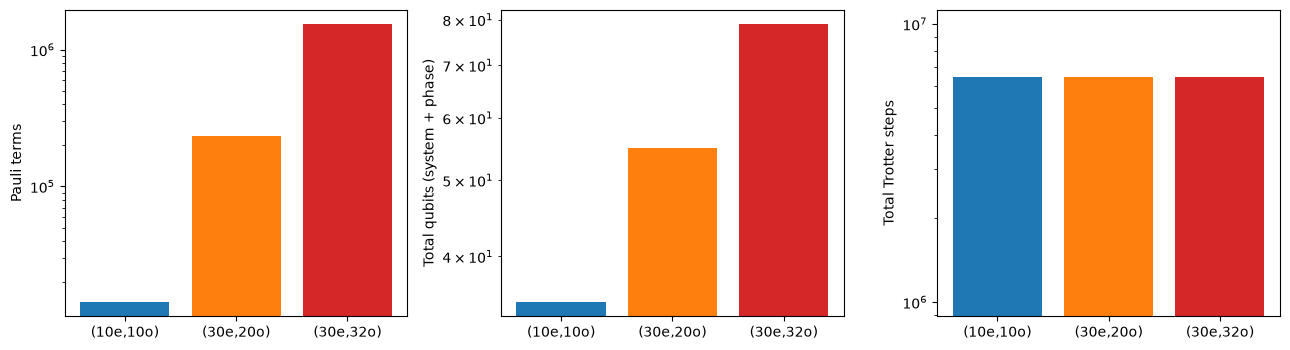

In [12]:
if df_res.empty:
    raise RuntimeError("No Fe2S2 FCIDUMPs found: run preparation.ipynb first.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, label in zip(
    axes,
    ["pauli_terms", "total_qubits", "trotter_steps"],
    ["Pauli terms", "Total qubits (system + phase)", "Total Trotter steps"],
):
    ax.bar(range(len(df_res)), df_res[col], color=["tab:blue", "tab:orange", "tab:red"])
    ax.set_xticks(range(len(df_res)), [n.split()[-1] for n in df_res.index])
    ax.set_yscale("log")
    ax.set_ylabel(label)
plt.tight_layout()

### Logical resources with DFTHC qubitisation

<div style="background-color: #d1ecf1; color: #0c5460; border-left: 5px solid #bee5eb; padding: 15px; margin-top: 15px; margin-bottom: 15px; border-radius: 4px;">
  <strong>ℹ️ To be added:</strong> Toffoli and logical-qubit counts from DFTHC qubitisation. They need a DFTHC factorisation of each active space, which comes from an external code and is not wired into this demo yet. The table above is laid out so those columns can be appended per system.
</div>

The cell below is where that step will go. It is also the second step, after the simulation, that we compare on CPU and GPU in Part 3.

In [ ]:
def dfthc_factorisation(system: System, device: str = "cpu"):
    """Placeholder: run the external DFTHC factorisation of `system` on `device` ("cpu" or "gpu")."""
    raise NotImplementedError("Hook up the external DFTHC factorisation here.")

# Part 3: CPU versus GPU

We compare CPU and GPU on the two steps that dominate the cost: the QPE **simulation** (this section) and the **DFTHC factorisation** used for the resource estimate (placeholder below).

## QPE simulation

Following Part 2 of the tutorial series, we time the same QPE circuit on each backend while increasing the number of phase qubits. The number of Trotter steps per controlled application is fixed at 1, so only the circuit width and the backend change. The CPU baseline uses `n_cores` threads. `fp64` is included because QPE at mHa resolution applies very long gate sequences, where single-precision rounding can accumulate.

In [ ]:
BACKENDS = {
    f"CPU ({n_cores} cores)": ("qpp-cpu", None),
    "GPU fp32": ("nvidia", None),
    "GPU fp64": ("nvidia", "fp64"),
}
CPU = next(iter(BACKENDS))


def backend_benchmark(phase_qubits, shots=100, repeats=2) -> pd.DataFrame:
    qpe = get_qpe(sq_ham, h, error=1.0)  # only provides time, order and the data-qubit count
    rows = []
    for label, (target, option) in BACKENDS.items():
        if target != "qpp-cpu" and not has_gpu:
            continue
        limit = max_qubits_cpu if target == "qpp-cpu" else max_qubits_gpu
        set_backend(target, option)  # circuits are rebuilt after every switch
        for m in phase_qubits:
            if qpe.num_data + m > limit:
                continue
            circuit, _ = qpe_circuit(qpe, h, dmrg, num_ancillas=m, reps=1)
            _, wall = time_sample(circuit, shots, repeats)
            rows.append(dict(backend=label, total_qubits=qpe.num_data + m, wall_s=wall))
            print(f"{label}: {qpe.num_data + m} qubits in {wall:.2f} s")
    set_backend(*TARGET)
    return pd.DataFrame(rows)


def speedup_table(df, x, baseline):
    """Wall times and speedups (baseline time / time) per backend, indexed by `x`."""
    wall = df.pivot(index=x, columns="backend", values="wall_s")
    return wall, wall.drop(columns=baseline).rdiv(wall[baseline], axis=0)


def plot_speedup(wall, speedup, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for col in wall:
        axes[0].semilogy(wall.index, wall[col], "o-", label=col)
    for col in speedup:
        axes[1].plot(speedup.index, speedup[col], "o-", label=col)
    axes[1].axhline(1, color="grey", ls=":")
    axes[0].set_ylabel("Wall time (s)")
    axes[1].set_ylabel(f"Speedup over {CPU}")
    for ax in axes:
        ax.set_xlabel(xlabel)
        ax.legend()
    plt.tight_layout()


df_bench = backend_benchmark(phase_qubits=[2, 4, 6, 8, 10, 12])
wall, speedup = speedup_table(df_bench, "total_qubits", CPU)
if has_gpu:
    plot_speedup(wall, speedup, "Total qubits")
    display(speedup.round(1))
else:
    print("No GPU detected: only the CPU timings are available.")
    display(wall.round(2))

## DFTHC factorisation

The same comparison for the factorisation step reuses `speedup_table` and `plot_speedup`: time `dfthc_factorisation(system, device)` for each device and active space, collect the times in a table with columns `backend`, `orbitals` and `wall_s`, and plot them. This runs once the external factorisation code is hooked in above.

In [ ]:
# Once dfthc_factorisation is implemented:
#
# rows = []
# for name, system in SYSTEMS.items():
#     for device, label in [("cpu", CPU), ("gpu", "GPU")]:
#         t0 = time.perf_counter()
#         dfthc_factorisation(system, device)
#         rows.append(dict(backend=label, orbitals=system.norb, wall_s=time.perf_counter() - t0))
# wall, speedup = speedup_table(pd.DataFrame(rows), "orbitals", CPU)
# plot_speedup(wall, speedup, "Active orbitals")

---

<div align="center">
  <h2>🎉 Demo Complete!</h2>
</div>

🏆 **What you've accomplished:**

- Ran ORCA and QPE for the chosen system and measured accuracy against cost
- Compared how large QPE gets for CAS(10e,10o), CAS(30e,20o) and CAS(30e,32o) at chemical accuracy
- Timed the same QPE circuit on CPU and GPU and measured the speedup

---